In [50]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import time
import src
import importlib
# allow reloading 
importlib.reload(src)

<module 'src' from 'c:\\Users\\jiyue\\OneDrive - UC San Diego\\python_projects\\corr\\src.py'>

## Introduction
We consider two strictly starionary random fields $X$ and $Y$ defined on the lattice $\mathbb{Z}^d$. The goal is to estimate the correlation between $X$ and $Y$, and compute the confidence interval and p value to capture the uncertaiy in estimation. 

## Examples

### Random field simulation 

Our method works for any dimension $d$. To illustrate this, we simulate two correlated random fields in 1D, 2D, and 3D and visualize each of them below.


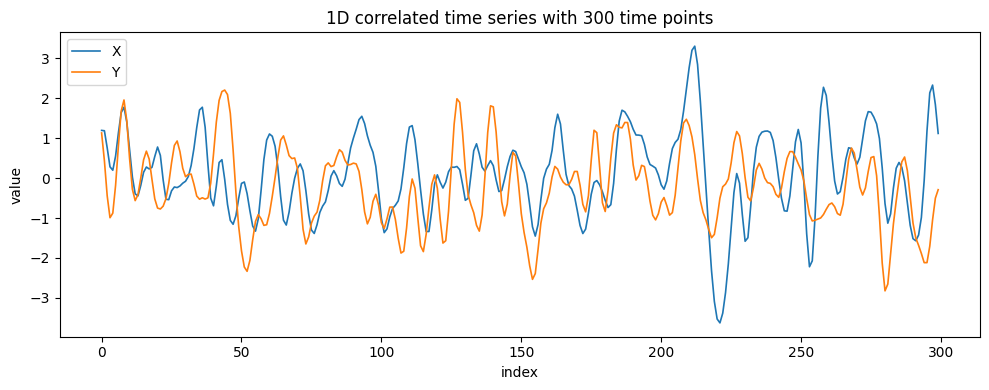

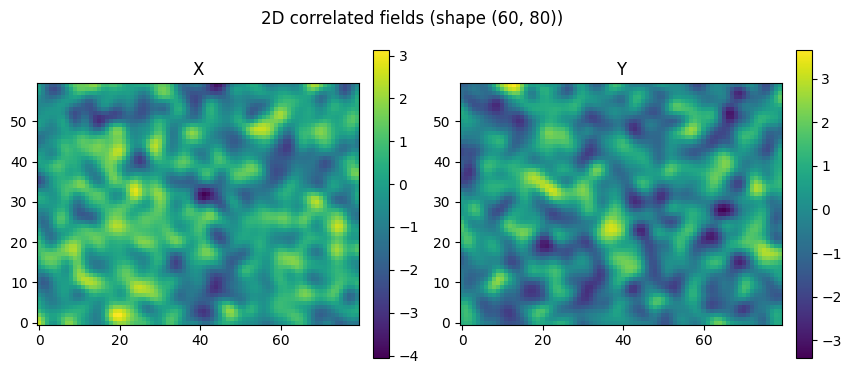

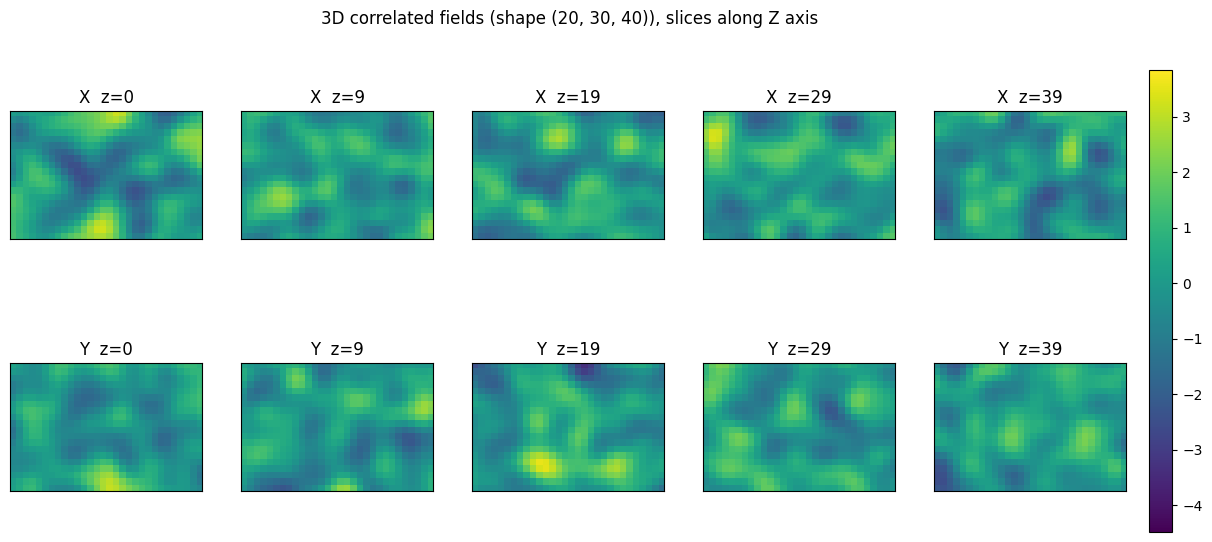

In [51]:
# specify true correlation between the two simulated random fields
rho = 0.3

# simulate 1D time series 
X1, Y1  =  src.gen_corr_field(rho = rho,
    dim=300)

# simulate 2D fields
X2, Y2  =  src.gen_corr_field(rho = rho,
    dim=(60, 80))

# simulate 3D fields
X3, Y3  =  src.gen_corr_field(rho = rho,
    dim=(20,30,40))


# visualize 1D time series
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(X1, label="X", lw=1.2)
ax.plot(Y1, label="Y", lw=1.2)
ax.set_xlabel("index")
ax.set_ylabel("value")
ax.set_title(f"1D correlated time series with {X1.shape[0]} time points")
ax.legend()
fig.tight_layout()
plt.show()

# visualize 2D fields 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, field, title in zip(axes, [X2, Y2], ["X", "Y"]):
    im = ax.imshow(field, origin="lower", cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04) 
fig.suptitle(f"2D correlated fields (shape {X2.shape})")
plt.show()

# visualize 3D fields as a montage of slices along the last axis
n_slices = 5
z_idx = np.linspace(0, X3.shape[2] - 1, n_slices).astype(int)

# shared color scale per field for comparable slices
vmin, vmax = min(X3.min(), Y3.min()), max(X3.max(), Y3.max())

fig, axes = plt.subplots(2, n_slices, figsize=(3 * n_slices, 6))
for row, (field, name) in enumerate(zip([X3, Y3], ["X", "Y"])):
    for col, z in enumerate(z_idx):
        ax = axes[row, col]
        im = ax.imshow(field[:, :, z], origin="lower", cmap="viridis",
                       vmin=vmin, vmax=vmax)
        ax.set_title(f"{name}  z={z}")
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
fig.suptitle(f"3D correlated fields (shape {X3.shape}), slices along Z axis ")
plt.show()




### Correlation between two random fields
Now we compute the correlation between the two random fields, along with its standard error (SE). We can choose different methods to compute the SE. Since typically we are also interested in hypothesis testing under the null of no correlation, the SE under the null is also computed. 

In [37]:
# compute SE, available methods: hac(default), hac_gaussian 
# 1D
rho_est1, se1, se_under_null1, *_ = src.corr(X1, Y1, se_method="hac")
print('----1D----\ncorrelation estimate:', rho_est1, '\nSE:', se1, '\nSE under null:', se_under_null1)

# 2D
rho_est2, se2, se_under_null2, *_ = src.corr(X2, Y2)
print('----2D----\ncorrelation estimate:', rho_est2, '\nSE:', se2, '\nSE under null:', se_under_null2)

# 3D
rho_est3, se3, se_under_null3, *_ = src.corr(X3, Y3)
print('----3D----\ncorrelation estimate:', rho_est3, '\nSE:', se3, '\nSE under null:', se_under_null3)

----1D----
correlation estimate: 0.3554766098539371 
SE: 0.09804672811541908 
SE under null: 0.11978563657805467
----2D----
correlation estimate: 0.3798076447497698 
SE: 0.03791402262202858 
SE under null: 0.05422726007795119
----3D----
correlation estimate: 0.29582315350104094 
SE: 0.027322796207113604 
SE under null: 0.0355320643940739


We can compute the confidence intervals (CI) and p values. By default, 95% CIs are computed and Fisher transformation is used for both CI computaton and p value calculation.

In [38]:
# compute confidence intervals, by default, 95% CI with Fisher transformation 
print('1D 95% CI:', src.confidence_interval(rho_est1, se1))
print('2D 95% CI:', src.confidence_interval(rho_est2, se2))
print('3D 95% CI:', src.confidence_interval(rho_est3, se3))

1D 95% CI: (0.15058134782923313, 0.5310899409680636)
2D 95% CI: (0.30316222047807845, 0.45157064428011306)
3D 95% CI: (0.24138889719327675, 0.34840167734986965)


In [39]:
# compute p value, by default with Fisher transformation 
print('1D p value:', src.pvalue(rho_est1, se_under_null1))
print('2D p value:', src.pvalue(rho_est2, se_under_null2))
print('3D p value:', src.pvalue(rho_est3, se_under_null3))

1D p value: 0.0019154900161038046
2D p value: 1.6653345369377348e-13
3D p value: 0.0


## Simulations
We can perform simulations to evaluate the coverage rate and power of the various variance estimation methods. 

In [63]:
# create various simulation settings
from itertools import product

# ---- factors to vary in the simulation study ----
# true correlation between the two fields 
rho_ls = [0, 0.4, -0.9, 0.9]
# number of spatial dimensions of the field (1D, 2D, 3D)
n_dim_ls = [1, 2, 3]
# side length of the d-dimensional square grid (field has nx**n_dim points)
nx_ls = [25, 50, 75, 100, 125, 150, 175, 200]
# smoothness of the field: full width at half maximum of the Gaussian kernel
fwhm_ls = [1, 2, 3, 4]
# noise distribution before smoothing
distribution_ls = ['gaussian']

# optional pointwise transform applied to the fields (None = identity, 'square' = X**2)
# sqaure a gaussian fields gives the chisq1 field
trans_ls = [None, 'square']
# field-generation method (smoothed noise via a Gaussian filter)
gen_method_ls = ['gaussian_filter']

# length scale (only used by the 'gstools' method; unused for 'gaussian_filter')
len_scale_ls = [None]
# degrees of freedom for the noise (only used for 't'/'chisq' distributions)
noise_df_ls = [None]

# take the Cartesian product of all factor levels -> one row per setting combination
setting_df = pd.DataFrame(
    product(nx_ls, n_dim_ls, rho_ls, len_scale_ls, fwhm_ls, gen_method_ls,
            distribution_ls, noise_df_ls, trans_ls),
    columns=['nx', 'n_dim', 'rho', 'len_scale', 'fwhm', 'gen_method',
             'distribution', 'noise_df', 'trans']
)
print(setting_df)


      nx  n_dim  rho len_scale  fwhm       gen_method distribution noise_df  \
0     25      1  0.0      None     1  gaussian_filter     gaussian     None   
1     25      1  0.0      None     1  gaussian_filter     gaussian     None   
2     25      1  0.0      None     2  gaussian_filter     gaussian     None   
3     25      1  0.0      None     2  gaussian_filter     gaussian     None   
4     25      1  0.0      None     3  gaussian_filter     gaussian     None   
..   ...    ...  ...       ...   ...              ...          ...      ...   
763  200      3  0.9      None     2  gaussian_filter     gaussian     None   
764  200      3  0.9      None     3  gaussian_filter     gaussian     None   
765  200      3  0.9      None     3  gaussian_filter     gaussian     None   
766  200      3  0.9      None     4  gaussian_filter     gaussian     None   
767  200      3  0.9      None     4  gaussian_filter     gaussian     None   

      trans  
0      None  
1    square  
2      No

In [59]:

from itertools import product

# ---- factors defining each SE-estimation method to compare ----
# lag-truncation rule for the HAC kernel ('auto' picks M from the field dimensions)
M_ls = ['auto']
# scaling constant applied to the chosen truncation lag M
constant_ls = [1]

# standard-error method:
#   'iid'          - assumes independent points (no spatial correlation)
#   'huristic'     - assume X and Y are independent
#   'hac'          - HAC estimator for the general case
#   'hac_gaussian' - HAC estimator for the Gaussian case
method_ls = ['iid', 'huristic', 'hac', 'hac_gaussian']

# kernel used to weight lags in the sum
kernel_ls = ['bartlett']

# whether to plug in the true rho in estimation (False = use the estimated rho)
use_true_rho_ls = [False]
# bandwidth for the QS kernel (None = not used for the bartlett kernel)
b_qs_ls = [None]

# Cartesian product of all factor levels -> one row per method configuration
method_df = pd.DataFrame(
    product(use_true_rho_ls, method_ls, kernel_ls, M_ls, b_qs_ls, constant_ls),
    columns=['use_true_rho', 'method', 'kernel', 'M', 'b_qs', 'constant']
)
print(method_df)


   use_true_rho        method    kernel     M  b_qs  constant
0         False           iid  bartlett  auto  None         1
1         False      huristic  bartlett  auto  None         1
2         False           hac  bartlett  auto  None         1
3         False  hac_gaussian  bartlett  auto  None         1


In [64]:
# test runs for a few settings 
# return_summary = True gives summaries of coverage and power; 
# set to False if you need raw results of each simulation replicate
src.sim_multiple(setting_df.head(), method_df, m_sim=50, return_summary = True)

----performing simulation, current setting number: 1, remaining settings: 4----
----performing simulation, current setting number: 2, remaining settings: 3----
----performing simulation, current setting number: 3, remaining settings: 2----
----performing simulation, current setting number: 4, remaining settings: 1----
----performing simulation, current setting number: 5, remaining settings: 0----


,setting_id,method_id,M0,bias_mean,est_sd,se_mean,n_se_na,cover_rate,cover_rate_raw,power,...,fwhm,distribution,noise_df,trans,use_true_rho,method,kernel,M,b_qs,constant
0,0,0,NaN,-0.022888,0.211578,0.191121,0,0.94,0.94,0.06,...,1,gaussian,None,None,False,iid,bartlett,auto,None,1
1,0,1,3.0,-0.022888,0.211578,0.191146,0,0.94,0.94,0.06,...,1,gaussian,None,None,False,huristic,bartlett,auto,None,1
2,0,2,3.0,-0.022888,0.211578,0.168408,0,0.84,0.82,0.04,...,1,gaussian,None,None,False,hac,bartlett,auto,None,1
3,0,3,3.0,-0.022888,0.211578,0.188833,0,0.96,0.94,0.04,...,1,gaussian,None,None,False,hac_gaussian,bartlett,auto,None,1
4,1,0,NaN,0.030572,0.256739,0.186894,0,0.84,0.84,0.16,...,1,gaussian,None,square,False,iid,bartlett,auto,None,1
5,1,1,3.0,0.030572,0.256739,0.187319,0,0.86,0.84,0.14,...,1,gaussian,None,square,False,huristic,bartlett,auto,None,1
6,1,2,3.0,0.030572,0.256739,0.144417,0,0.72,0.68,0.02,...,1,gaussian,None,square,False,hac,bartlett,auto,None,1
7,1,3,3.0,0.030572,0.256739,0.186384,0,0.84,0.84,0.12,...,1,gaussian,None,square,False,hac_gaussian,bartlett,auto,None,1
8,2,0,NaN,0.021147,0.271122,0.185503,0,0.82,0.80,0.18,...,2,gaussian,None,None,False,iid,bartlett,auto,None,1
9,2,1,3.0,0.021147,0.271122,0.236167,0,0.96,0.88,0.04,...,2,gaussian,None,None,False,huristic,bartlett,auto,None,1
